# 0. Project Overview – Telco Customer Churn

## Summary

A churn model and a cost-based retention policy for 7,043 clients of a telecom company. The models are trained on 80% of the clients and all reported results come from the remaining 1,409 test clients.

- **Churn can be predicted well, and a simple model is enough ([Modeling Results](#modeling-results)):** a logistic regression reaches a test average precision (AP) of $0.653$, about $2.5$ times the churn rate of $0.265$ that a random ranking would score. A tuned XGBoost model is only slightly better ($0.660$), so the logistic regression is kept for its simplicity and interpretability.
- **The predicted probabilities can be trusted ([Calibration](#calibration)):** both models are well calibrated, so their probabilities can be used directly in profit calculations.
- **Short tenure, month-to-month contracts and fiber-optic internet go with the highest churn ([EDA](#2-exploratory-data-analysis)):** $47\%$ of clients in their first year churn, $43\%$ of month-to-month clients and $42\%$ of fiber-optic clients, compared with $3\%$ of clients on two-year contracts.
- **Without a model, a retention campaign loses money ([Business Model Results](#business-model-results)):** offering the best uniform discount to every test client loses $2{,}043$ (in units of monthly charges), because most of the discount goes to clients who would have stayed anyway.
- **With the model, the campaign becomes profitable:** instead of one uniform discount, every client gets the offer with the highest expected profit, and only the most promising clients are targeted. Targeting the top $26.54\%$ of clients by expected profit earns $10{,}679$ with $374$ offers ($28.6$ per offer); the most profitable campaign size is about $30\%$ of clients ($10{,}889$).

The business results depend on assumptions about how clients respond to discounts, which should be checked with an A/B test before the policy is used.

## The Goal of the Project

Losing a client costs a telecom company all of that client's future revenue, but retention offers cost money too, and most clients would stay without one. The goal of this project is to predict which clients are likely to churn and to turn these predictions into a **retention policy**: whom to offer a discount, how large and for how long, so that the expected profit is as high as possible. The project is meant for data scientists building churn models and for marketing and retention teams deciding where to spend their budget.

## Main Questions to Answer

[__*Q1.*__](#modeling-results) How well can churn be predicted, and which model is the most suitable and convenient to use?

[__*Q2.*__](#calibration) Are the predicted churn probabilities reliable enough to be used directly in profit calculations?

[__*Q3.*__](#business-model-results) Which clients should receive a retention discount, and which offer, to maximize the expected profit?

[__*Q4.*__](#business-model-results) How much does the model add compared with a campaign run without one?

## The Data

This project uses the [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data) dataset published on Kaggle. It is an IBM sample dataset that, according to [IBM](https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113), describes a fictional telecom company providing home phone and internet services to $7{,}043$ clients in California in one quarter (Q3). It has $21$ columns: the client ID, demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account information (`tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`), the subscribed services (phone, internet, online security, backup, device protection, tech support, streaming) and the target `Churn`, which shows whether the client left within the last month. $26.54\%$ of the clients churned.

## Project Structure

The project consists of 5 parts:
1. [Preliminaries](#1-preliminaries)
Imports, loading the data and a basic inspection.
2. [Exploratory Data Analysis](#2-exploratory-data-analysis)
Churn rates by contract, tenure and internet service, and the distributions of monthly charges and tenure.
3. [Modeling](#3-modeling)
Preprocessing, a logistic regression baseline, a tuned XGBoost model and a calibration check.
4. [Business Model](#4-business-model)
A model of a discount-based retention action, the best offer for every client and a comparison of five targeting strategies on the test set.
5. [Conclusions](#5-conclusions)
Modeling and business results, limitations, business recommendations and suggestions for future analysis.

# 1. Preliminaries

## Importing Packages

In [1]:
# Basic imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Preprocessing
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Modeling
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
import optuna

# Validation
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import average_precision_score


# Suppressing warnings
warnings.filterwarnings('ignore')

# For displaying all of the columns in dataframes
pd.set_option('display.max_columns', None)

In [2]:
# Plot style shared by all charts below
BLUE, GOLD, RED, GREY = '#3757C6', '#87750D', '#C6666A', '#8C8C8C'

def clean_axes(ax, grid_axis='y'):
	ax.spines[['top', 'right']].set_visible(False)
	ax.grid(axis=grid_axis, color='#E5E5E5', linewidth=0.8)
	ax.set_axisbelow(True)
	return ax

## Loading and Inspecting the Data

In [3]:
data_path = 'docs/data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(data_path, index_col='customerID')

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Data info
df.info()

<class 'pandas.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 

In [5]:
print(f'Total missing values {df.isna().sum().sum()}')
print(f'Data shape: {df.shape}')

Total missing values 0
Data shape: (7043, 20)


In [6]:
df.select_dtypes(exclude='number').apply(func=lambda x: (x == ' ').sum(), axis='index')

gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64

In [7]:
df[['TotalCharges', 'MonthlyCharges']].apply(func=lambda x: (x == '0').sum(), axis='index')

TotalCharges      0
MonthlyCharges    0
dtype: int64

There are $11$ missing values in the `TotalCharges` column. They are stored as blank strings (`' '`) rather than `NaN`, which is why `isna()` does not find them and why the whole column is read as text. All $11$ clients have a tenure of $0$ months: they are new clients who have not been billed yet, so their total charges are imputed with zeros. The other columns don't contain any missing values.

# 2. Exploratory Data Analysis

## Churn Rate by Key Features

The dashed line marks the overall churn rate in the dataset.

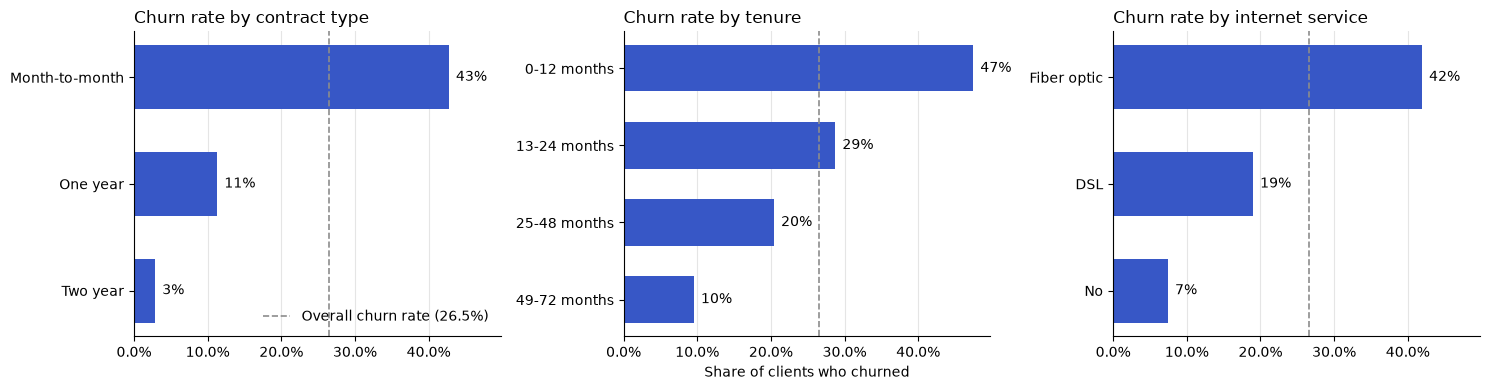

In [8]:
eda = df.copy()
eda['Churned'] = (eda['Churn'] == 'Yes').astype(int)
eda['TenureGroup'] = pd.cut(
	eda['tenure'], bins=[-1, 12, 24, 48, 72],
	labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months']
)
overall_rate = eda['Churned'].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, col, title in zip(
	axes,
	['Contract', 'TenureGroup', 'InternetService'],
	['Contract type', 'Tenure', 'Internet service']
):
	rates = eda.groupby(col, observed=True)['Churned'].mean().sort_values()
	ax.barh(rates.index.astype(str), rates.values, color=BLUE, height=0.6)
	ax.axvline(overall_rate, color=GREY, linestyle='--', linewidth=1.2, label=f'Overall churn rate ({overall_rate:.1%})')
	for i, v in enumerate(rates.values):
		ax.text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=10)
	ax.set_title(f'Churn rate by {title.lower()}', loc='left')
	ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
	clean_axes(ax, grid_axis='x')
axes[0].legend(frameon=False, loc='lower right')
axes[1].set_xlabel('Share of clients who churned')
fig.tight_layout()
plt.show()

All three features show large differences in churn rates:
- **Contract type:** $43\%$ of month-to-month clients churn, compared with $11\%$ on one-year and $3\%$ on two-year contracts. More than half of all clients ($55\%$) have a month-to-month contract.
- **Tenure:** churn is highest in the first year ($47\%$) and falls steadily with tenure, to $10\%$ for clients who have stayed more than four years.
- **Internet service:** $42\%$ of fiber-optic clients churn, more than twice as many as DSL clients ($19\%$), while only $7\%$ of clients without internet service leave.

These features are related to each other (for example, long-tenure clients are more often on long contracts), so the differences should not be added up.

## Monthly Charges and Tenure by Churn Status

Densities are normalized separately for each group, so the shapes can be compared even though there are fewer churners.

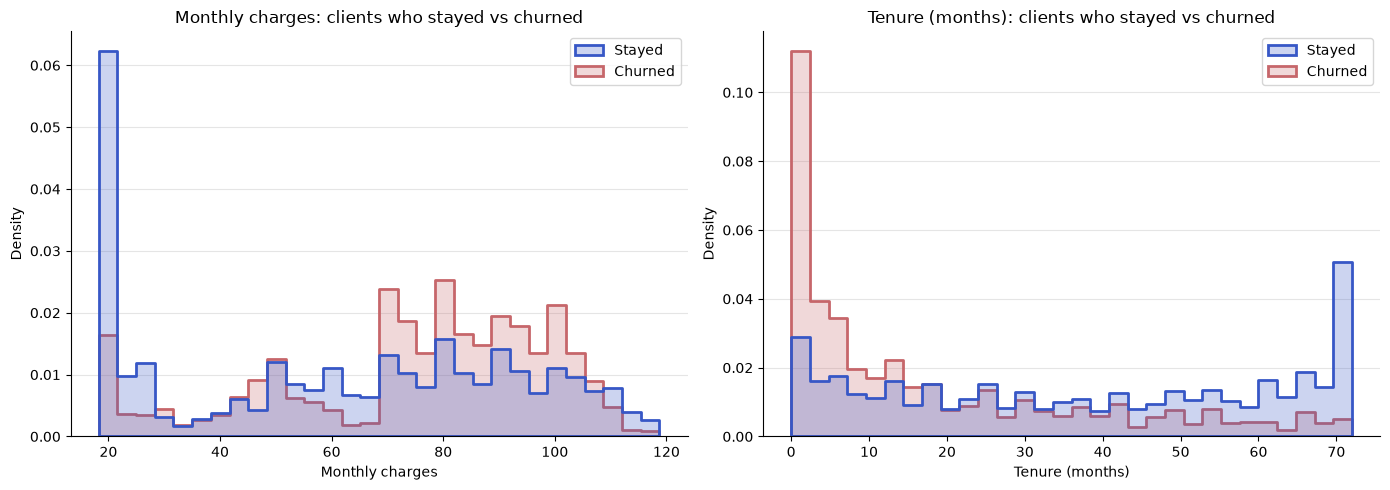

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, label in zip(axes, ['MonthlyCharges', 'tenure'], ['Monthly charges', 'Tenure (months)']):
	sns.histplot(
		data=eda, x=col, hue='Churn', hue_order=['No', 'Yes'],
		palette={'No': BLUE, 'Yes': RED}, stat='density', common_norm=False,
		element='step', fill=True, alpha=0.25, linewidth=2, bins=30, ax=ax
	)
	ax.set_title(f'{label}: clients who stayed vs churned', loc='center')
	ax.set_xlabel(label)
	clean_axes(ax)
	ax.get_legend().set_title(None)
	for text, new in zip(ax.get_legend().texts, ['Stayed', 'Churned']):
		text.set_text(new)
fig.tight_layout()
plt.show()

- **Monthly charges:** clients who stayed have a large peak at the lowest charges (about $20$–$25$), mostly clients without internet service, while churners are concentrated between about $70$ and $105$. The mean monthly charge is $74.4$ for churners and $61.3$ for clients who stayed.
- **Tenure:** churners are concentrated in the first months (median tenure $10$ months, and $56\%$ of churners left within their first year), while clients who stayed are spread over the whole range, with a peak at the maximum of $72$ months (median $38$ months).

New clients with high monthly charges are therefore the group with the highest churn risk.

# 3. Modeling

## Preprocessing

We split the data into a training set ($80\%$, $5{,}634$ clients) and a test set ($20\%$, $1{,}409$ clients), stratified by churn, so both sets have the same churn rate. All model selection uses 5-fold stratified cross-validation on the training set; the test set is used only for the final comparison and for the business model.

All models share one **preprocessing transformer**, built as a `ColumnTransformer`:
- **numeric features** (`tenure`, `TotalCharges`, `MonthlyCharges`): conversion to numbers (the blank `TotalCharges` values become `NaN`), imputation with zeros and standard scaling;
- **binary features** (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `gender`): one-hot encoding into a single 0/1 column each;
- **categorical features** (the services, `Contract` and `PaymentMethod`): one-hot encoding, with unknown categories ignored;
- `SeniorCitizen` is already 0/1 and is passed through unchanged; `customerID` is dropped.

Because the transformer is part of each model's pipeline, it is refit inside every cross-validation fold, so no information from the validation folds leaks into training.

In [10]:
def to_num(X):
	return X.apply(pd.to_numeric, errors='coerce')

X = df.drop(columns=['Churn'])
y = (df['Churn'] == 'Yes').astype('int64')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

cat_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
			'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
			'Contract', 'PaymentMethod', 'OnlineBackup'
			]
num_cols = ['tenure', 'TotalCharges', 'MonthlyCharges']
bin_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'gender']

num_pipe = Pipeline(
	[
		('to_numeric', FunctionTransformer(to_num, feature_names_out='one-to-one')),
		('impute', SimpleImputer(strategy='constant', fill_value=0)),
		('scale', StandardScaler())
	]
)

preprocess = ColumnTransformer(
	[
		('num', num_pipe, num_cols),
		('bin', OneHotEncoder(drop='if_binary', sparse_output=False), bin_cols),
		('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
		('keep', 'passthrough', ['SeniorCitizen']) # already 1/0
	],
	remainder='drop'
).set_output(transform='pandas')

## Linear Baseline Model

We start with a simple baseline: a logistic regression on the preprocessed features, evaluated with 5-fold stratified cross-validation on the training set.

As the metric we use **average precision (AP)**, the area under the precision-recall curve. It measures how well a model ranks churners above non-churners and focuses on the minority class, which matters here because only about a quarter of the clients churn. A random ranking would score about the churn rate ($0.2654$).

In [11]:
linear_model = Pipeline(
	[
		('preprocess', preprocess),
		('model', LogisticRegression(max_iter=1000))
	]
)

ap_linear_baseline = cross_val_score(
	linear_model, X_train, y_train,
	cv=StratifiedKFold(n_splits=5), 
	scoring='average_precision'
).mean()

print(f'Linear model average precision : {ap_linear_baseline:.4f}')

Linear model average precision : 0.6556


In [12]:
linear_model.fit(X_train, y_train)

clf = linear_model[-1]
names = linear_model[:-1].get_feature_names_out()

coefs = pd.Series(clf.coef_[0], index=names)
coefs.sort_values(key=abs, ascending=False).head(15)

num__tenure                                 -1.400548
cat__Contract_Two year                      -0.809544
num__TotalCharges                            0.707165
cat__Contract_Month-to-month                 0.564412
cat__InternetService_DSL                    -0.561201
cat__InternetService_Fiber optic             0.423075
bin__PaperlessBilling_Yes                    0.339304
num__MonthlyCharges                         -0.333976
cat__OnlineSecurity_Yes                     -0.277979
cat__MultipleLines_No                       -0.271673
cat__DeviceProtection_No internet service   -0.271013
cat__OnlineBackup_No internet service       -0.271013
cat__StreamingMovies_No internet service    -0.271013
cat__StreamingTV_No internet service        -0.271013
cat__OnlineSecurity_No internet service     -0.271013
dtype: float64

Positive coefficients raise the predicted churn risk, negative ones lower it. The strongest effects come from `tenure` (longer tenure, lower risk), the contract type (a two-year contract lowers the risk, a month-to-month contract raises it) and the internet service (fiber optic raises the risk, DSL lowers it), which matches the [EDA](#2-exploratory-data-analysis).

`tenure`, `TotalCharges` and `MonthlyCharges` are strongly correlated and share their effect between them, so their individual coefficients (including their signs) should not be interpreted on their own. The same applies to the five identical "No internet service" coefficients, which all describe the same clients.

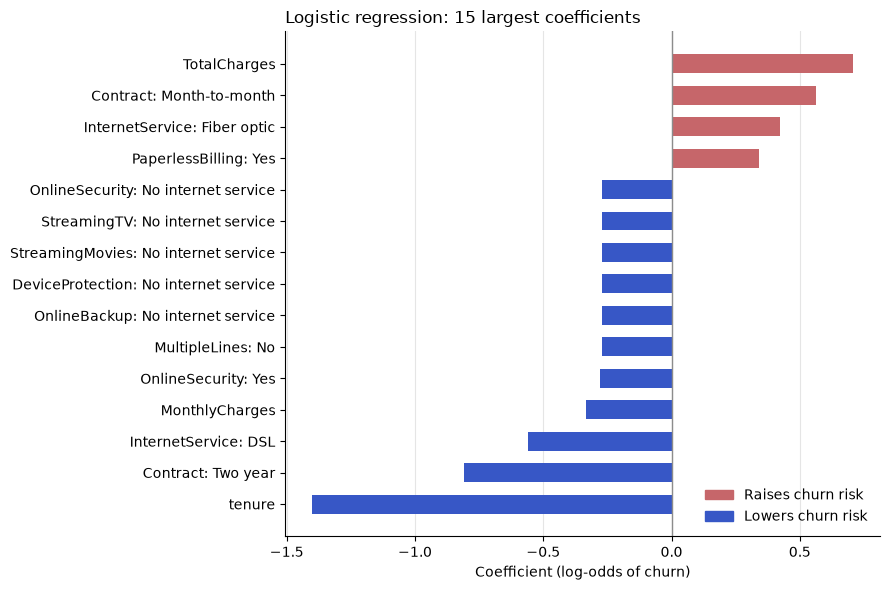

In [13]:
def readable(name):
	# 'cat__Contract_Month-to-month' -> 'Contract: Month-to-month', 'num__tenure' -> 'tenure'
	group, feature = name.split('__', 1)
	if group in ('bin', 'cat'):
		column, value = feature.split('_', 1)
		return f'{column}: {value}'
	return feature

top = coefs.sort_values(key=abs, ascending=False).head(15).sort_values()
colors = [RED if v > 0 else BLUE for v in top.values]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([readable(name) for name in top.index], top.values, color=colors, height=0.6)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_title('Logistic regression: 15 largest coefficients', loc='left')
ax.set_xlabel('Coefficient (log-odds of churn)')
ax.legend(
	handles=[
		plt.matplotlib.patches.Patch(color=RED, label='Raises churn risk'),
		plt.matplotlib.patches.Patch(color=BLUE, label='Lowers churn risk'),
	],
	frameon=False, loc='lower right'
)
clean_axes(ax, grid_axis='x')
fig.tight_layout()
plt.show()

## Gradient Boosting Model

Next, we check whether a more flexible model can capture effects that the logistic regression misses, such as non-linear relationships and interactions between features. **XGBoost** builds an ensemble of decision trees one after another, with each new tree correcting the errors of the previous ones.

We first evaluate XGBoost with its default hyperparameters, using the same preprocessing and cross-validation as the baseline. Then we tune its hyperparameters with Optuna: 100 trials of a Bayesian search (TPE sampler with a fixed seed), each scored by the mean cross-validated AP on the training set. The search takes several minutes, so its cell is commented out and does not run with *Run All*; uncomment it to repeat the search. Finally, both models are compared on the test set.

In [14]:
xgb = XGBClassifier(
	random_state=0,
	n_jobs=-1,
	objective="binary:logistic",
	eval_metric=["logloss", "aucpr"]
)
xgb_model = Pipeline(
	[
		('preprocessing', preprocess),
		('model', xgb)
	]
)
ap_xgb = cross_val_score(
	xgb_model, X_train, y_train, 
	cv=StratifiedKFold(n_splits=5), 
	scoring='average_precision'
).mean()
print(f'XGB Average Precision : {ap_xgb:.4f}')

XGB Average Precision : 0.6245


With its default hyperparameters, XGBoost (CV AP $0.6245$) performs worse than the logistic regression ($0.6556$): the default trees are deep enough to overfit the training folds. Tuning should show whether a better-regularized version can beat the baseline.

In [15]:
'''
def objective(trial):
	params = {
		'n_estimators': trial.suggest_int('n_estimators', 200, 3000), 
		'learning_rate': trial.suggest_float('learning_rate', 0.0005, 0.5, log=True), 
		'max_depth': trial.suggest_int('max_depth', 2, 10),
		'subsample': trial.suggest_float('subsample', 0.2, 1.0),
		'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0), 
		'reg_lambda': trial.suggest_float('reg_lambda', 0.0001, 20.0, log=True), 
		'reg_alpha': trial.suggest_float('reg_alpha', 0.0001, 10.0, log=True), 
		'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
	}

	xgb_tuned = XGBClassifier(
		**params,
		random_state=0,
		n_jobs=-1,
		objective="binary:logistic",
		eval_metric=["logloss", "aucpr"]
	)
	xgb_model_tuned = Pipeline(
		[
			('preprocessing', preprocess),
			('model', xgb_tuned)
		]
	)
	score = cross_val_score(
		xgb_model_tuned, X_train, y_train, 
		cv=StratifiedKFold(n_splits=5),
		scoring='average_precision'
	).mean()
	
	return score

study = optuna.create_study(
	direction='maximize',
	sampler=optuna.samplers.TPESampler(seed=0),  # fixed seed -> same suggestions every run
)

study.optimize(objective, n_trials=100, n_jobs=1)  # trials one at a time: parallel trials break reproducibility

print("Best hyperparameters : ", study.best_params)
print(f"Best Average Precision : {study.best_value:.4f}")
'''
print('Uncomment the lines above to run the Optuna hyperparameters search')

Uncomment the lines above to run the Optuna hyperparameters search


The search was run once with the seed above. Its best trial reached a mean CV AP of $0.6733$ with shallow trees (`max_depth=4`), a small learning rate and many trees. Its hyperparameters are hard-coded below, so that the final model can be refit without re-running the search, and both models are then fit on the whole training set and evaluated on the test set.

In [16]:
best_parameters = {
	'n_estimators': 2175, 
	'learning_rate': 0.0017684897247340803, 
	'max_depth': 4, 
	'subsample': 0.7055692756065363, 
	'colsample_bytree': 0.5516612874868294, 
	'reg_lambda': 0.01559147437443147, 
	'reg_alpha': 0.05117520004182674, 
	'min_child_weight': 6
}
# best_parameters = study.best_params

final_xgb = XGBClassifier(random_state=0, eval_metric=["logloss", "aucpr"], **best_parameters)
final_model = Pipeline(
	[
		('preprocess', preprocess),
		('model', final_xgb)
	]
)
final_model.fit(X_train, y_train)
y_pred_xgb = final_model.predict_proba(X_test)[:, 1]

linear_model.fit(X_train, y_train)
y_pred_lin = linear_model.predict_proba(X_test)[:, 1]
print(f'Test set AP (linear model): {average_precision_score(y_test, y_pred_lin):.4f}')
print(f'Test set AP (xgb): {average_precision_score(y_test, y_pred_xgb):.4f}')
print(f'Test set churn rate: {sum(y_test) / len(y_test):.4f}')

Test set AP (linear model): 0.6534
Test set AP (xgb): 0.6602
Test set churn rate: 0.2654


| Model | CV AP (training set) | Test AP |
|---|---|---|
| Logistic regression | $0.6556$ | $0.6534$ |
| XGBoost, default | $0.6245$ | – |
| XGBoost, tuned | $0.6733$ | $0.6602$ |

The *tuned XGBoost model* performs only slightly better than the *logistic regression* on the test set ($\text{AP}_{lin}=0.6534 \to \text{AP}_{xgb}=0.6602$), an improvement of less than $0.01$ that is within the noise of a single test set of $1{,}409$ clients. Both models rank churners about $2.5$ times better than random ($0.2654$).

The complex model therefore adds almost nothing compared with the simple linear classifier, which is faster, easier to interpret and to explain to business users, and needs no hyperparameter search. We use the **logistic regression's probabilities** in the business model below.

## Calibration

The business model uses the predicted probabilities $p(c)$ directly, so they need to be *calibrated*: among clients with a predicted churn probability of about $0.3$, about $30\%$ should actually churn. Points close to the dashed diagonal mean that the probabilities can be used as they are; the histogram below shows how many test clients fall into each probability range.

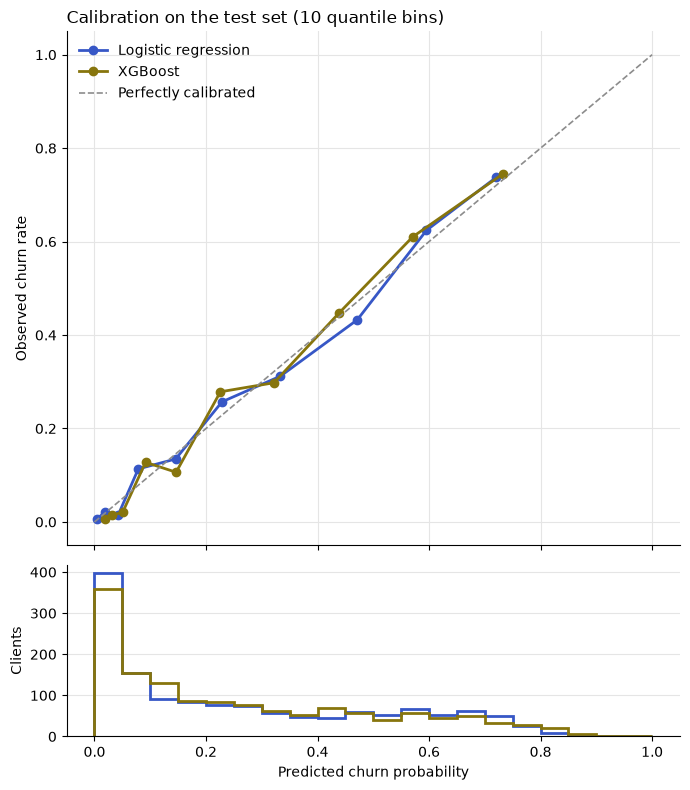

In [17]:
from sklearn.calibration import CalibrationDisplay

fig, (ax, ax_hist) = plt.subplots(
	2, 1, figsize=(7, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]}
)
for proba, name, color in [(y_pred_lin, 'Logistic regression', BLUE), (y_pred_xgb, 'XGBoost', GOLD)]:
	CalibrationDisplay.from_predictions(
		y_test, proba, n_bins=10, strategy='quantile', name=name, ax=ax,
		color=color, marker='o', linewidth=2, ref_line=False
	)
	ax_hist.hist(proba, bins=20, range=(0, 1), histtype='step', linewidth=2, color=color, label=name)
ax.plot([0, 1], [0, 1], linestyle='--', color=GREY, linewidth=1.2, label='Perfectly calibrated')
ax.set_title('Calibration on the test set (10 quantile bins)', loc='left')
ax.set_xlabel('')
ax.set_ylabel('Observed churn rate')
ax.legend(frameon=False, loc='upper left')
clean_axes(ax, grid_axis='both')
ax_hist.set_xlabel('Predicted churn probability')
ax_hist.set_ylabel('Clients')
clean_axes(ax_hist)
fig.tight_layout()
plt.show()

Both calibration curves follow the diagonal closely across the whole range, and the predictions are concentrated at low probabilities, as expected with a churn rate of about $27\%$. The table below adds two summary measures: **ROC-AUC** (the probability that a random churner gets a higher score than a random non-churner; bigger is better) and the **Brier score** (the mean squared error of the probabilities; lower is better). The no-skill baseline predicts the training churn rate for every client.

In [18]:
from sklearn.metrics import roc_auc_score, brier_score_loss

no_skill = np.full(len(y_test), y_train.mean())   # predicting the training churn rate for everyone
metrics = pd.DataFrame({
	name: {
		'Average precision': average_precision_score(y_test, proba),
		'ROC-AUC': roc_auc_score(y_test, proba),
		'Brier score': brier_score_loss(y_test, proba),
		'Mean predicted probability': proba.mean(),
	}
	for name, proba in [('Logistic regression', y_pred_lin), ('XGBoost', y_pred_xgb), ('No-skill baseline', no_skill)]
}).T
print(f'Actual churn rate on the test set: {y_test.mean():.4f}')
metrics.round(4)

Actual churn rate on the test set: 0.2654


,Average precision,ROC-AUC,Brier score,Mean predicted probability
Logistic regression,0.6534,0.8516,0.1339,0.2640
XGBoost,0.6602,0.8533,0.1329,0.2628
No-skill baseline,0.2654,0.5000,0.1950,0.2654


Both models are clearly better than the no-skill baseline and almost identical to each other: the logistic regression reaches ROC-AUC $0.852$ and a Brier score of $0.134$ (XGBoost: $0.853$ and $0.133$). Their mean predicted probabilities ($0.264$ and $0.263$) match the actual test churn rate ($0.265$), so neither model systematically over- or underestimates churn. The probabilities can therefore be used directly in the expected-profit calculations.

# 4. Business Model

The model tells us *who* is likely to churn. This section turns its probabilities into decisions: which clients should receive a retention offer, which offer, and how much profit this brings compared with running a campaign without a model.

## Retention Action Strategy

For the sake of simplicity, and because we have no data on how effective different retention actions are, we assume a single retention action: a discount of fixed size for a fixed period (in months). Below are the definitions and assumptions we use to make the business model more precise.

A list of definitions:
- $p(c)$ - churn probability without any action (predicted by the model)
- $m$ - monthly revenue of the client
- $d$ - discount size (%), chosen from a fixed menu $d \in \{0, 10, 15, \dots, 50\}$
- $t$ - discount period (months), $t \in \{0, 1, \dots, 24\}$
- $H$ - evaluation horizon (months), $H \ge t$; we use $H = 24$
- $e(d, t)$ - discount effectiveness: the share of would-be churners the discount retains
- $e_{max}$ - maximum possible effectiveness
- $p(R)$ - probability that the client stays after receiving the discount
- $\mu$ - contribution margin: the share of revenue kept as profit after the costs of serving the client
- $R_0$ - expected revenue without any action
- $R_e$ - expected revenue after making a discount
- $L$ - expected loss on the retention action (revenue given away as discount)
- $c_0$ - fixed cost of making an offer (contacting the client and setting the offer up)
- $P_e$ - expected profit gain from making the offer, compared with not making it

A list of main assumptions (made using logical reasoning):
- $p(R)$ is increasing in $d$: $\frac{\partial p(R)}{\partial d} > 0$
- $p(R)$ is increasing in $t$: $\frac{\partial p(R)}{\partial t} > 0$
- A discount needs both a size and a duration to have any effect: $e(0, t) = e(d, 0) = 0$
- The discount never lowers retention: $p(R) \ge 1 - p(c)$
- Not every would-be churner can be retained: $e(d, t) \le e_{max} = 0.6$
- A retained client pays for the whole horizon $H$: $m \cdot (1 - \frac{d}{100})$ during the discount period and $m$ afterwards
- The contribution margin is $\mu = 0.6$, based on typical telecom gross margins of about $60\%$ (e.g. T-Mobile US $59.7\%$ in 2023, Deutsche Telekom $61.4\%$)
- Every offer has a fixed cost of $c_0 = 2$, paid for every client who receives an offer, regardless of the offer's size and of whether the client stays
- Discounts are only offered from a fixed menu of standard sizes ($10$%, $15$%, ..., $50$%): a company runs a few standard offers, and very small discounts are not noticeable to clients

We'll also assume that:
1. The effect of $d$ and $t$ on $e$ shows diminishing returns: the first percents and months of discount matter most, and each additional one adds less.
2. $d$ matters more than $t$.

Taking all the assumptions above into account, the discount acts on the churn side: it retains a share $e(d, t)$ of the clients who would otherwise leave.

$$e(d, t) = e_{max} \cdot \left(\frac{d}{100}\right)^{a} \cdot \left(\frac{t}{24}\right)^{b}, \qquad 0 < b < a < 1$$

$$p(R) = 1 - p(c) \cdot \big(1 - e(d, t)\big)$$

where $a$ and $b$ are the elasticities of $e$ with respect to $d$ and $t$: a 1% increase in $d$ raises $e$ by $a$%, and a 1% increase in $t$ raises it by $b$%. Assumption 1 is therefore $a, b < 1$, and assumption 2 is $a > b$. We use $a = 0.7$, $b = 0.6$.

Because $d$ and $t$ are multiplied, a discount with zero size or zero duration has no effect. Because the effect is applied to the churn probability, $p(R)$ never falls below the no-action baseline $1 - p(c)$ and never exceeds $1 - p(c)(1 - e_{max})$.

We can then calculate $R_0$, $R_e$, $L$ and $P_e$ as

$$R_0 = \big(1 - p(c)\big) \cdot m \cdot H$$

$$R_e = p(R) \cdot m \cdot \left(H - t \cdot \frac{d}{100}\right)$$

$$L = p(R) \cdot m \cdot t \cdot \frac{d}{100}$$

$$P_e = \mu \cdot \underbrace{\big[p(R) - \big(1 - p(c)\big)\big] \cdot m \cdot H}_{\text{revenue saved}} - L - c_0$$

for any actual offer ($d > 0$ and $t > 0$); making no offer gives $P_e = 0$. The discount is offered only if $P_e > 0$.

Note that $L$ is weighted by $p(R)$, the total probability that the client stays, and not only by the uplift $p(R) - (1 - p(c))$. A client who churns anyway pays nothing and therefore receives no discount, but a client who would have stayed anyway still receives it. This is why offers to low-risk clients are usually unprofitable.

The margin $\mu$ applies only to the revenue saved: a retained client brings back revenue but also the costs of serving them, while a discount reduces revenue without reducing any cost, so every unit of discount is lost in full.

Unlike $L$, the fixed cost $c_0$ is not weighted by $p(R)$: it is paid for every client who receives an offer, whether they stay or not. It also rules out offers that are too small to matter in practice (such as a 1% discount for one month), whose expected gain cannot cover the cost of making them.

**Limitations of the business model:**
- $e_{max}$, $a$, $b$ and $c_0$ are assumptions, not estimates, and the recommended offer depends heavily on them.
- The margin $\mu = 0.6$ is a benchmark, not the company's actual figure: the dataset contains no cost data, and published telecom gross margins (about $60\%$) only approximate the contribution margin of a single subscriber. EBITDA margins (about $30$–$45\%$) would understate it, because they include costs that do not change when one client leaves. Margins also vary considerably between operators and countries.
- Because the cost of an offer grows with $d \cdot t$ while its effect grows with $d^a t^b$ and $a > b$, the most profitable offer always uses the maximum discount size with a short period. The upper bound on $d$ is therefore a business constraint that directly shapes the recommendation.
- A retained client is assumed to pay for the whole horizon $H$; churn after retention is ignored.

The results should therefore be checked with a sensitivity analysis over $e_{max}$, $a$, $b$, $c_0$ and $\mu$ (roughly $0.4$–$0.8$), and the parameters replaced with estimates from an A/B test and the company's cost data once they are available.

## Targeting Strategies

Using the fitted logistic regression, we estimate the churn probability $p(c)_i$ of every client $i$ in the test set and find the offer that maximizes their expected profit gain:

$$(d_i^*, t_i^*) = \arg\max_{d \in \{0, 10, 15, \dots, 50\},\ t \in \{0, \dots, 24\}} P_e\big(d, t \mid p(c)_i, m_i\big), \qquad P_i^* = P_e\big(d_i^*, t_i^* \mid p(c)_i, m_i\big)$$

An offer with $d = 0$ or $t = 0$ means "no offer": no fixed cost is paid and $P_e = 0$, so $P_i^* \ge 0$ for every client.

Because both the revenue saved and the loss are proportional to $m$, while $c_0$ is the same for every offer, the monthly revenue does not change *which* offer is best: $(d_i^*, t_i^*)$ depends only on $p(c)_i$ and the model parameters. It does change *whether* the offer is worth making: the gain grows with $m_i$ but the fixed cost does not, so low-revenue clients need a higher churn probability before an offer pays off.

The churn rate in the training data is $\bar p = 0.2654$. A model-free company would assume this probability for every client. With our parameters, no offer is profitable at $\bar p$: its expected gain does not cover $c_0$ even for the highest monthly revenue in the data, so a model-free company would make no offers at all. To see what running a campaign without a model would cost, we force strategies 1 and 2 to run one anyway, using the best *actual* offer (excluding "no offer"), which is the same for every client:

$$(\bar d, \bar t) = \arg\max_{d > 0,\ t > 0} P_e\big(d, t \mid \bar p\big)$$

With our parameters this is a $10$% discount for $1$ month, which has a negative expected gain for every client.

We compare five strategies:

| # | Strategy | Targeted clients $S$ | Offer |
|---|---|---|---|
| 1 | Random 26.54% | a random $26.54\%$ of clients | uniform $(\bar d, \bar t)$ |
| 2 | Everybody | all clients | uniform $(\bar d, \bar t)$ |
| 3 | Positive expected profit | $\{i : P_i^* > 0\}$ | individual $(d_i^*, t_i^*)$ |
| 4 | Top 26.54% by risk | top $26.54\%$ by $p(c)_i$ | individual $(d_i^*, t_i^*)$ |
| 5 | Top 26.54% by expected profit | top $26.54\%$ by $P_i^*$ | individual $(d_i^*, t_i^*)$ |

Strategies 1, 4 and 5 target the same number of clients ($26.54\%$, the churn rate, i.e. $374$ of the $1{,}409$ test clients), so they compare *how* clients are chosen at equal reach. Strategy 3 sets no limit on reach.

In [19]:
def e(d, t, e_max=0.6, a=0.7, b=0.6):
	return e_max * (d / 100) ** a * (t / 24) ** b

def p_R(p_c, eff):
	return 1 - p_c * (1 - eff)

def L(pr, m, t, d):
	return pr * m * t * d / 100

def P_e(m, t, d, p_c, H=24, mu=0.6, e_max=0.6, a=0.7, b=0.6, c_0=2.0):
	if d == 0 or t == 0:
		return 0.0  # no offer: no discount and no fixed cost
	eff = e(d, t, e_max=e_max, a=a, b=b)
	pr = p_R(p_c, eff)
	loss = L(pr, m, t, d)
	return mu * (pr - (1 - p_c)) * m * H - loss - c_0

D_MENU = [0] + list(range(10, 50 + 1, 5))  # 0 = no discount
T_RANGE = range(0, 24 + 1)

def find_best_offer(m, p_c, allow_no_offer=True, d_menu=D_MENU, t_range=T_RANGE, **params):
	# allow_no_offer=False forces a campaign: returns the best actual offer even if its P_e < 0
	best_offer = (0, 0, 0.0) if allow_no_offer else (0, 0, float('-inf'))  # (d, t, expected_profit)
	for t in t_range:
		for d in d_menu:
			if d == 0 or t == 0:
				continue  # "no offer" is already the starting point
			expected_profit = P_e(m, t, d, p_c, **params)
			if expected_profit > best_offer[2]:
				best_offer = (d, t, expected_profit)
	return best_offer

### Best Offer Map

The best offer $(d^*, t^*)$ for every combination of churn probability and monthly revenue: the color shows the discount size and the number the discount period in months. Grey cells get no offer. The boundary of the grey region moves to the left as $m$ grows: because of the fixed cost $c_0$, low-revenue clients need a higher churn probability before an offer pays off.

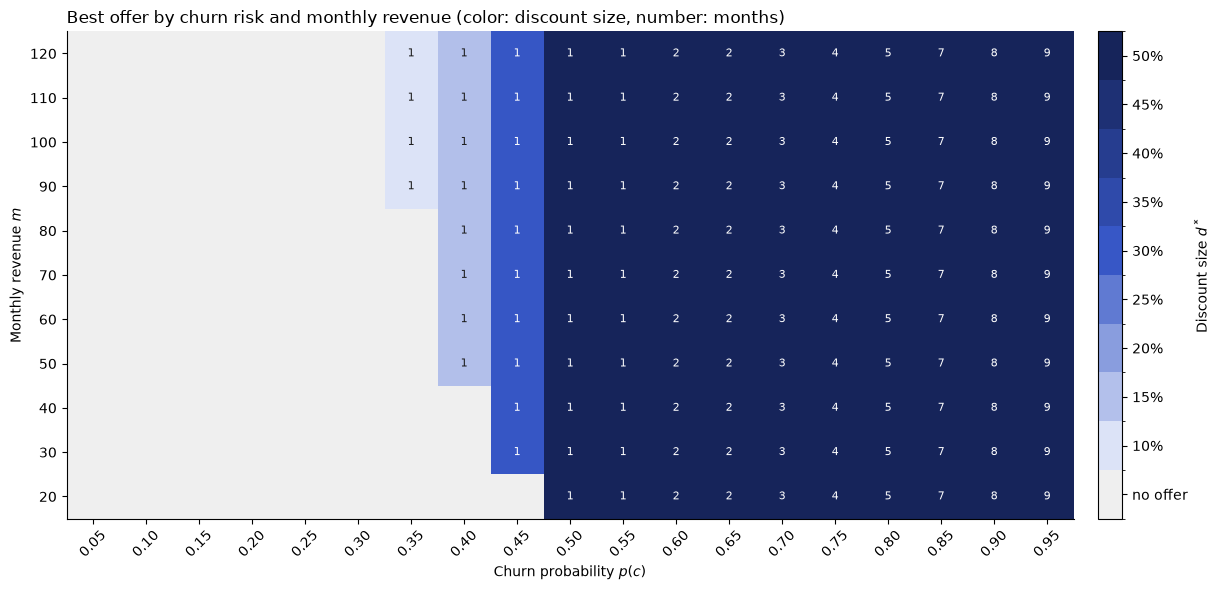

In [20]:
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap

p_grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
m_grid = np.arange(20, 121, 10)
d_star = np.zeros((len(m_grid), len(p_grid)))
t_star = np.zeros((len(m_grid), len(p_grid)), dtype=int)
for i, m in enumerate(m_grid):
	for j, p_c in enumerate(p_grid):
		d, t, _ = find_best_offer(m, p_c)
		d_star[i, j], t_star[i, j] = d, t

d_levels = D_MENU                                   # 0 = no offer, then 10, 15, ..., 50
ramp = LinearSegmentedColormap.from_list('blues', ['#DCE3F7', BLUE, '#16245A'])
colors = ['#EFEFEF'] + [ramp(x) for x in np.linspace(0, 1, len(d_levels) - 1)]
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(len(d_levels) + 1) - 0.5, cmap.N)
level_idx = np.vectorize(d_levels.index)(d_star.astype(int))

fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(level_idx, cmap=cmap, norm=norm, aspect='auto', origin='lower')
for i in range(len(m_grid)):
	for j in range(len(p_grid)):
		if t_star[i, j] > 0:
			text_color = 'white' if level_idx[i, j] >= 5 else '#1A1A1A'
			ax.text(j, i, f'{t_star[i, j]}', ha='center', va='center', fontsize=8, color=text_color)
ax.set_xticks(range(len(p_grid)), [f'{p:.2f}' for p in p_grid], rotation=45)
ax.set_yticks(range(len(m_grid)), m_grid)
ax.set_xlabel('Churn probability $p(c)$')
ax.set_ylabel('Monthly revenue $m$')
ax.set_title('Best offer by churn risk and monthly revenue (color: discount size, number: months)', loc='left')
cbar = fig.colorbar(im, ax=ax, ticks=range(len(d_levels)), pad=0.02)
cbar.ax.set_yticklabels(['no offer'] + [f'{d}%' for d in d_levels[1:]])
cbar.set_label('Discount size $d^*$')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

Offers start to pay off at a churn probability of about $0.35$–$0.5$, depending on the monthly revenue. Below $0.5$, the best offers are small (a $10$–$30\%$ discount for one month); from $0.5$ onwards, the best offer always uses the maximum discount of $50\%$, and only its duration grows with the risk, from $1$ month at $p(c)=0.5$ to $9$ months at $p(c)=0.95$. This is the effect described in the limitations above: since $a > b$, the discount size is used up before the period is extended.

### Evaluation

Each strategy chooses its offers using its own assumptions, but all strategies are evaluated with the observed churn label $y_i \in \{0, 1\}$ of the test clients, which does not depend on the model. Substituting $y_i$ for $p(c)$ in $P_e$ gives the realized profit gain of an offer:

$$\pi_i(d, t) = y_i \cdot \Big[\mu \cdot e(d, t) \cdot m_i \cdot H - e(d, t) \cdot m_i \cdot t \cdot \frac{d}{100}\Big] - (1 - y_i) \cdot m_i \cdot t \cdot \frac{d}{100} - c_0$$

- a client who would have churned ($y_i = 1$) is retained with probability $e(d, t)$, bringing back $\mu \cdot m_i \cdot H$ minus the discount;
- a client who would have stayed ($y_i = 0$) stays anyway and only receives the discount;
- in both cases, the fixed cost $c_0$ of making the offer is paid.

The total profit gain of a strategy is

$$\Pi = \sum_{i \in S} \pi_i(d_i, t_i)$$

compared with $\Pi = 0$ for taking no action. The random strategy in the table below is a single draw (`random_state=0`); its expected value is $\Pi_1 = 0.2654 \cdot \Pi_2$, and the cell after the table shows its spread over $1{,}000$ random draws.

Evaluating with the model's own probabilities instead of $y_i$ would make strategy 3 optimal by construction, because it targets exactly the clients for whom the model predicts a positive gain. The label-based evaluation shows whether the model's probabilities are good enough for that to hold on unseen clients.

For each strategy, the table below reports the number of offers made, the total discount given (expected, from the predicted probabilities, and real, from the observed labels), the total fixed cost ($c_0$ times the number of offers made), the total expected and real profit gain $\Pi$, and the average expected and real profit gain per offer.

In [21]:
def real_profit(m, t, d, y, **params):
	return P_e(m, t, d, y, **params)

def offer_table(X, y, p_churn, allow_no_offer=True, **params):
	p_churn = np.broadcast_to(p_churn, len(y))
	e_params = {k: params[k] for k in ('e_max', 'a', 'b') if k in params}
	c_0 = params.get('c_0', 2.0)  # same default as in P_e
	rows = []
	for m, p_c, churned in zip(X['MonthlyCharges'], p_churn, y):
		d, t, p_exp = find_best_offer(m, p_c, allow_no_offer=allow_no_offer, **params)
		eff = e(d, t, **e_params)
		offer_made = d > 0 and t > 0
		rows.append({
			'ChurnProba': p_c,
			'Churned': churned,
			'DiscountSize': d,
			'DiscountTime': t,
			'ExpectedProfit': p_exp,
			'RealProfit': real_profit(m, t, d, churned, **params),
			'ExpectedLoss': L(p_R(p_c, eff), m, t, d),
			'RealLoss': L(p_R(churned, eff), m, t, d),
			'FixedCost': c_0 if offer_made else 0.0,
		})
	return pd.DataFrame(rows, index=X.index)

def summarize(offer_df):
	offers = offer_df[(offer_df['DiscountSize'] > 0) & (offer_df['DiscountTime'] > 0)]
	return pd.Series({
		'Offers Made': len(offers),
		'Total Expected Loss (discounts)': offers['ExpectedLoss'].sum(),
		'Total Real Loss (discounts)': offers['RealLoss'].sum(),
		'Total Fixed Cost': offers['FixedCost'].sum(),
		'Total Expected Profit': offers['ExpectedProfit'].sum(),
		'Average Expected Profit per Offer': offers['ExpectedProfit'].mean(),
		'Total Real Profit': offers['RealProfit'].sum(),
		'Average Real Profit per Offer': offers['RealProfit'].mean(),
	})

P_BAR = 0.2654

naive = offer_table(X_test, y_test, P_BAR, allow_no_offer=False)
smart = offer_table(X_test, y_test, y_pred_lin)

k = round(P_BAR * len(y_test))  # ~P_BAR of all clients in the test set
results = pd.DataFrame({
	f'Random {P_BAR:.2%}': summarize(naive.sample(k, random_state=0)),
	'Everybody': summarize(naive),
	'Positive expected profit': summarize(smart[smart['ExpectedProfit'] > 0]),
	f'Top {P_BAR:.2%} by risk': summarize(smart.nlargest(k, 'ChurnProba')),
	f'Top {P_BAR:.2%} by expected profit': summarize(smart.nlargest(k, 'ExpectedProfit')),
}).T

results

,Offers Made,Total Expected Loss (discounts),Total Real Loss (discounts),Total Fixed Cost,Total Expected Profit,Average Expected Profit per Offer,Total Real Profit,Average Real Profit per Offer
Random 26.54%,374.0,1840.314896,1711.633454,748.0,-896.520008,-2.397112,-432.336021,-1.155979
Everybody,1409.0,6911.165373,6541.715088,2818.0,-3375.755815,-2.395852,-2043.062425,-1.450009
Positive expected profit,458.0,13614.447425,13221.458127,916.0,9996.749011,21.826963,10780.385030,23.537959
Top 26.54% by risk,374.0,12865.551707,12510.330903,748.0,9836.609054,26.301094,10509.348573,28.099862
Top 26.54% by expected profit,374.0,12953.641603,12553.206849,748.0,9872.412679,26.396825,10679.470060,28.554733


**Without the model, the campaign loses money.** Offering the uniform $10\%$ discount for $1$ month to everybody loses $2{,}043$, and offering it to a random $26.54\%$ of the clients loses $432$ in this draw (about $1.2$–$1.5$ per offer). Most of the discount goes to clients who would have stayed anyway, while the offer retains too few of the would-be churners.

**With the model, all three targeting strategies are profitable:**
- *Positive expected profit* earns the most in total ($10{,}780$), but needs $458$ offers ($23.5$ per offer).
- *Top 26.54% by expected profit* earns $10{,}679$, i.e. $99\%$ of that, with $18\%$ fewer offers ($374$), and has the highest profit per offer ($28.6$).
- *Top 26.54% by risk* earns slightly less ($10{,}509$), because it ignores monthly revenue: it also targets risky clients with low bills, for whom the offer pays off less.

For the model-based strategies, the real profit is $7$–$8\%$ higher than the expected profit, which agrees with the good calibration of the probabilities. For the strategies without a model, the real losses are smaller than expected, because churners pay higher monthly charges on average (see the [EDA](#monthly-charges-and-tenure-by-churn-status)), so the few clients who are retained are worth more than the average client.

The single random draw above is one possible outcome. The cell below repeats it $1{,}000$ times.

In [22]:
random_profits = pd.Series([
	naive.sample(k, random_state=seed)['RealProfit'].sum()
	for seed in range(1000)
])
print(f'Random {P_BAR:.2%} of clients, 1000 random draws:')
print(f' - mean total real profit: {random_profits.mean():.1f}')
print(f' - 90% of draws between {random_profits.quantile(0.05):.1f} and {random_profits.quantile(0.95):.1f}')
print(f' - share of draws with a profit: {(random_profits > 0).mean():.1%}\n')
print(f'Expected value ({P_BAR} x Everybody): {P_BAR * naive["RealProfit"].sum():.1f}')

Random 26.54% of clients, 1000 random draws:
 - mean total real profit: -542.9
 - 90% of draws between -882.7 and -221.7
 - share of draws with a profit: 0.2%

Expected value (0.2654 x Everybody): -542.2


Over $1{,}000$ random draws, targeting a random $26.54\%$ of the clients loses $543$ on average, which matches the expected value $0.2654 \cdot \Pi_2 = -542$, and $90\%$ of the draws lose between $222$ and $883$. Only $0.2\%$ of the draws make any profit, so the loss is not bad luck: a campaign without a model reliably loses money.

### Cumulative Profit

Clients are sorted by expected profit (or by churn risk) and targeted from the top. Each line shows the cumulative *real* profit, evaluated with the observed churn labels, as more clients are targeted. The peak marks the most profitable campaign size; clients beyond the positive-expected-profit cutoff get no offer, so the lines flatten. The dashed line is the expected path of a campaign without a model (random order, uniform offer).

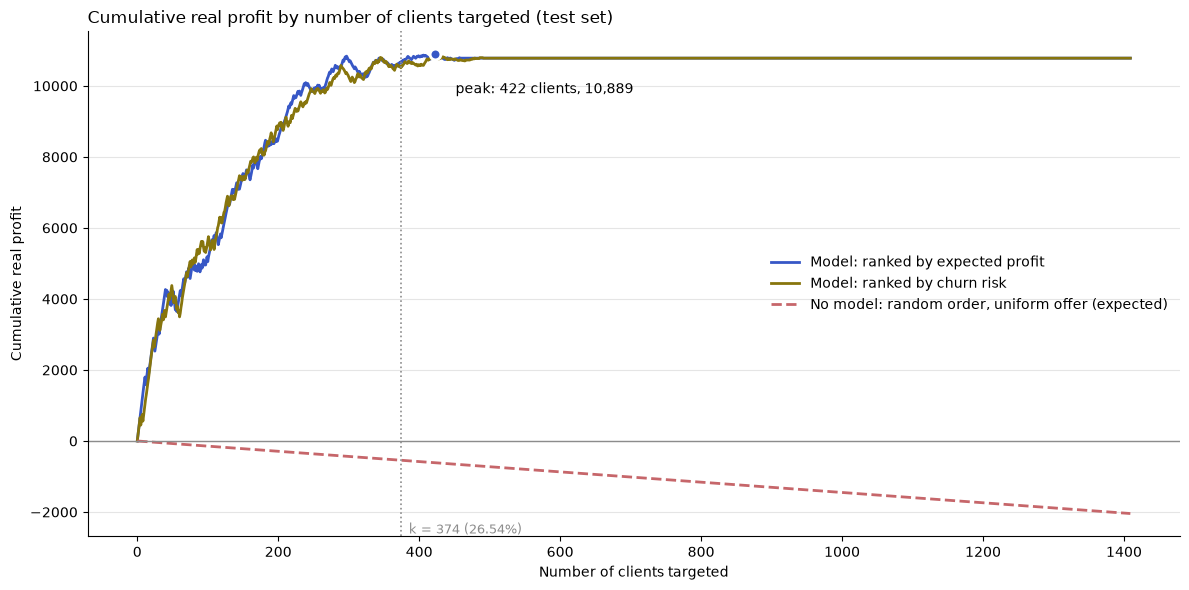

In [23]:
n_clients = len(smart)
x = np.arange(0, n_clients + 1)

def cumulative(series):
	return np.concatenate([[0.0], series.cumsum().to_numpy()])

by_value = cumulative(smart.sort_values('ExpectedProfit', ascending=False)['RealProfit'])
by_risk = cumulative(smart.sort_values('ChurnProba', ascending=False)['RealProfit'])
no_model = x * naive['RealProfit'].mean()          # random order, uniform offer: expected path

fig, ax = plt.subplots(figsize=(12, 6))
for y_vals, label, color, style in [
	(by_value, 'Model: ranked by expected profit', BLUE, '-'),
	(by_risk, 'Model: ranked by churn risk', GOLD, '-'),
	(no_model, 'No model: random order, uniform offer (expected)', RED, '--'),
]:
	ax.plot(x, y_vals, color=color, linewidth=2, linestyle=style, label=label)

best_k = int(np.argmax(by_value))
ax.scatter([best_k], [by_value[best_k]], s=60, color=BLUE, zorder=3, edgecolor='white', linewidth=2)
ax.annotate(
	f'peak: {best_k} clients, {by_value[best_k]:,.0f}',
	(best_k, by_value[best_k]), xytext=(15, -28), textcoords='offset points', fontsize=10
)
ax.axvline(k, color=GREY, linestyle=':', linewidth=1.2)
ax.text(k, ax.get_ylim()[0], f'  k = {k} ({P_BAR:.2%})', color=GREY, fontsize=9, va='bottom')
ax.axhline(0, color=GREY, linewidth=1)
ax.set_title('Cumulative real profit by number of clients targeted (test set)', loc='left')
ax.set_xlabel('Number of clients targeted')
ax.set_ylabel('Cumulative real profit')
ax.legend(frameon=False, loc='center right')
clean_axes(ax)
fig.tight_layout()
plt.show()

- **Ranked by expected profit**, the cumulative profit rises steeply over the first $250$–$300$ clients and peaks at $10{,}889$ after $422$ clients ($30\%$ of the test set). After the peak, the line stays almost flat: these clients add little, and those beyond the positive-expected-profit cutoff get no offer at all.
- **Ranked by churn risk**, the curve is very similar and peaks slightly lower ($10{,}838$ after $419$ clients), confirming that the risk ranking already captures most of the value.
- **Without a model**, every additional client adds an expected loss of about $1.45$, so the campaign ends at $-2{,}043$ when everybody is targeted.

The first clients in the ranking bring most of the profit, so a campaign limited to about the top $25$–$30\%$ of clients loses very little compared with the optimum.

# 5. Conclusions

## Modeling Results

| Model | CV AP | Test AP | Test ROC-AUC | Test Brier score |
|---|---|---|---|---|
| Logistic regression | $0.6556$ | $0.6534$ | $0.852$ | $0.134$ |
| XGBoost, default | $0.6245$ | – | – | – |
| XGBoost, tuned | $0.6733$ | $0.6602$ | $0.853$ | $0.133$ |
| No-skill baseline | – | $0.2654$ | $0.500$ | $0.195$ |

- **Both models predict churn well:** on the test set they rank churners about $2.5$ times better than random (AP $0.65$–$0.66$ vs $0.27$) and reach a ROC-AUC of about $0.85$.
- **Tuning matters for XGBoost, but not enough:** the default XGBoost model is worse than the logistic regression in cross-validation ($0.6245$ vs $0.6556$); after tuning, it is slightly better ($0.6733$ in CV, $0.6602$ vs $0.6534$ on the test set). The gain of less than $0.01$ AP is within the noise of a single test set.
- **The logistic regression is the better choice for this problem.** It is almost as accurate, much simpler and faster, needs no hyperparameter search, and its coefficients can be explained directly to business users. A complex model would be worth its cost only if the small gain in AP brought a measurable gain in profit.
- **The strongest churn drivers** are short tenure, month-to-month contracts and fiber-optic internet; long contracts and DSL go with low churn. These are associations, not causes: for example, a fiber-optic connection may simply be more common among clients with other reasons to leave.
- **Both models are well calibrated** ([Calibration](#calibration)): the calibration curves follow the diagonal, the mean predicted probability ($0.264$) matches the test churn rate ($0.265$), and the Brier score ($0.134$) is well below the no-skill baseline ($0.195$). This is what allows the probabilities to be used directly in the business model, and it is confirmed there: the real profit of the model-based strategies is $7$–$8\%$ above the expected profit.

## Business Model Results

Results on the $1{,}409$ test clients, evaluated with the observed churn labels (in units of monthly charges):

| Strategy | Offers | Total real profit | Real profit per offer |
|---|---|---|---|
| Random 26.54% (uniform offer) | $374$ | $-432$ (mean of $1{,}000$ draws: $-543$) | $-1.2$ |
| Everybody (uniform offer) | $1{,}409$ | $-2{,}043$ | $-1.5$ |
| Positive expected profit | $458$ | $10{,}780$ | $23.5$ |
| Top 26.54% by risk | $374$ | $10{,}509$ | $28.1$ |
| Top 26.54% by expected profit | $374$ | $10{,}679$ | $28.6$ |

- **A campaign without a model loses money.** With the average churn rate, no discount covers its cost: the best uniform offer ($10\%$ for $1$ month) loses about $1.45$ per client, and only $0.2\%$ of $1{,}000$ random campaigns make any profit.
- **The model turns the campaign into a profit of about $10{,}500$–$10{,}900$**, a difference of about $11{,}000$–$13{,}000$ compared with a campaign without a model.
- **Ranking by expected profit beats ranking by risk** at the same number of offers ($10{,}679$ vs $10{,}509$), because it also takes the client's monthly revenue into account.
- **Targeting the top $26.54\%$ by expected profit** keeps $99\%$ of the profit of targeting every client with a positive expected profit while making $18\%$ fewer offers, and gives the highest profit per offer.
- **The cumulative profit peaks after $422$ clients ($30\%$ of the test set) at $10{,}889$**; beyond that, additional offers add nothing.
- **The best offers are concentrated:** for clients above a churn probability of about $0.5$, the best offer always uses the maximum discount of $50\%$, for $1$ to $9$ months depending on the risk.

## Limitations

- **Assumed response to discounts.** The effectiveness of a discount ($e_{max}$, $a$, $b$) is assumed, not estimated, because the data contain no retention campaigns. The recommended offers and the profit figures depend heavily on these assumptions.
- **Assumed costs.** The margin ($\mu=0.6$) is an industry benchmark and the fixed cost per offer ($c_0=2$) a guess; the dataset contains no cost data.
- **Simplified client behavior.** A retained client is assumed to stay for the whole 24-month horizon and to keep paying the same monthly charges; churn after retention, price changes and the time value of money are ignored.
- **Churn labels as a stand-in for the future.** The evaluation assumes that a client who churned would have churned without an offer and that the others would have stayed. In reality, the labels describe what happened, not what would happen after an offer.
- **One test set and one point in time.** All results come from a single split with $1{,}409$ test clients and a snapshot of a fictional company, so small differences (such as $0.007$ AP between the models) are not meaningful, and the models are not validated on future data.
- **Correlation, not causation.** Features such as fiber-optic internet or paperless billing are associated with churn but do not necessarily cause it, so changing them would not necessarily reduce churn.

## Business Recommendations

1. **Don't run untargeted retention campaigns.** At the average churn rate, a discount mostly pays clients who would have stayed anyway, and the campaign loses money.
2. **Rank clients by expected profit and target the top of the list.** Targeting the top $25$–$30\%$ of clients by expected profit is the most reliable strategy: it earns almost as much as targeting everyone with a positive expected profit ($99\%$), makes fewer offers, gives the highest profit per offer and fits naturally into a fixed campaign budget. It is also less sensitive to the exact cutoff, because the clients near the cutoff add very little either way.
3. **Size the campaign by the cumulative profit curve.** In this data the optimum is about $30\%$ of the clients; stopping earlier loses little, while targeting everybody turns the profit into a loss.
4. **Focus on the highest-risk groups:** new clients, month-to-month contracts and fiber-optic internet. Encouraging longer contracts at the start of the relationship is a natural first retention measure.
5. **Keep the model simple and monitored.** Use the logistic regression, and re-check its calibration regularly, because the profit calculations rely on the probabilities being accurate.

## Future Analysis

- **A/B tests of retention actions.** Offer different discounts (sizes and durations) and other retention actions to randomly selected high-risk clients and compare them with a control group. This would replace the assumed effectiveness $e(d, t)$ with measured values and show which actions actually work.
- **Personalized retention actions.** A simple discount is rarely the best action for every client. Personalized actions, such as a tailored data plan for heavy users, an upgrade or a gift on the client's birthday, or a call from support after service problems, are likely to work better in most cases. They require more personal data (e.g. birthday, age, traffic and service usage, support interactions) and an uplift model that predicts how each client responds to each action, not only whether they would churn.
- **Sensitivity analysis.** Repeat the business evaluation over a range of $e_{max}$, $a$, $b$, $c_0$ and $\mu$ to see which recommendations hold under all plausible assumptions.
- **Time to churn.** A survival model would estimate *when* a client is likely to leave and how long a retained client stays, replacing the fixed 24-month horizon.
- **Real costs and validation over time.** Use the company's actual cost data instead of benchmarks, and validate the model on clients from later periods rather than on a random split.